# Fig 1F, 1H · Fast retrieval (the two parts of the old overview's panel F)

**Run first:** `R0_index_cache` (staged cells, tiles and the seed-0 split) → `R2_whole_tile` (the typical breast query,
`results/whole_tile/band/breast_cancer.npz`) and `R4_timing` (`results/timing/whole_tile.csv`).
Login node, spindle_env (the figure font).

* **F** The typical breast query of Fig 3C (seed 0, g = 0.25) on the section: the query tile and Spindle's first 10 tiles
  (its own order) over every cell and the quadtree tiles.
* **H** End-to-end time per query (query logarithms + search, summed per query; one thread; median per seed, mean
  over seeds 0–4) of Spindle and the whole-matrix scan, as Fig 2B: the query logarithms hatched (from the axis), then
  the search (solid); labels give Spindle's end-to-end speed-up over the whole-matrix scan (4 Nov: was search only).

Fig 1 itself (`figures/fig1_overview/`) is the user's own figure and is never written; this notebook writes
`figures/fig1_panel_f/panels/{F,H}.{pdf,png}` only (PDF vector, PNG 600 dpi), for the user to place.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import data
import style as ps
import whole_tile as wt

FIG = "fig1_panel_f"  # not fig1_overview: that folder is the user's own figure
ps.DPI = 600  # this figure only (user, 1 Nov); style.py keeps 1200 for the others
KEY = "breast_cancer"
TOP = 10
BAND = ROOT / "results" / "whole_tile" / "band" / f"{KEY}.npz"
TIMING = ROOT / "results" / "timing" / "whole_tile.csv"
KEYS = ps.DATASET_ORDER
SPINDLE, WHOLE = ps.TIER_COLORS["spindle"], ps.TIER_COLORS["whole"]
W_MAP, W_T, H_T = 45.0, 55.0, 46.0
VECTOR_CELLS = True  # cells as vector points in the PDF (zoom-safe); False rasterises them at 1200 dpi

band = np.load(BAND)
split = np.load(data.cache_dir(KEY, int(band["seed"])) / "split.npz")
assert int(band["seed"]) == data.EXAMPLE_SEED and int(split["test"][int(band["query"])]) == int(band["test_tile"])
bbox = np.load(data.CACHE / KEY / "tiles.npz")["bbox"]  # prepare() tile order: (xmin, ymin, xmax, ymax)
xy = np.load(data.CACHE / KEY / "cells.npz")["xy"]
q_box = bbox[int(band["test_tile"])]
hits = split["train"][band["found"][:TOP]]  # Spindle's first 10 index rows -> tile indices
_, timing = wt.timing_tables(pd.read_csv(TIMING))
timing = timing.set_index("key")
print(f"{KEY}: query tile {int(band['test_tile'])}, {int(band['n_found'])} tiles returned, {len(xy):,} cells, "
      f"{len(bbox):,} tiles; timing {sorted(set(timing.tag))}")

breast_cancer: query tile 953, 484 tiles returned, 159,226 cells, 2,044 tiles; timing ['method-v2']


## F · The query and Spindle's first 10 tiles on the breast section

figures/fig1_panel_f/panels/F.pdf/.png: 45 x 39 mm, 2.1 / 0.6 MB


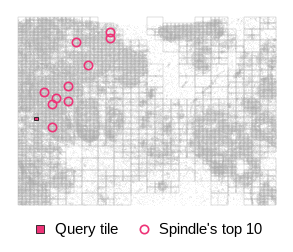

In [2]:
def panel_map(fig):
    W, H = ps.size_mm(fig)
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    pad = 0.01 * (x1 - x0)
    x0, x1, y0, y1 = x0 - pad, x1 + pad, y0 - pad, y1 + pad
    ax = ps.axes(fig, bottom=6.0)
    ax.scatter(xy[:, 0], xy[:, 1], s=0.02, c="#BDBDBD", lw=0, rasterized=not VECTOR_CELLS, zorder=1)
    ax.add_collection(PatchCollection([Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1]) for b in bbox],
                                      fc="none", ec="#9E9E9E", lw=0.15, zorder=2))
    c = bbox[hits]
    ax.plot((c[:, 0] + c[:, 2]) / 2, (c[:, 1] + c[:, 3]) / 2, ls="", marker="o", ms=4.0, mfc="none",
            mec=ps.QUERY_COLOR, mew=0.8, zorder=4)
    ax.add_patch(Rectangle((q_box[0], q_box[1]), q_box[2] - q_box[0], q_box[3] - q_box[1], fc=ps.QUERY_COLOR,
                           ec=ps.INK, lw=0.4, zorder=5))
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # image orientation
    ax.set_aspect("equal")
    ax.axis("off")
    handles = [Line2D([], [], ls="", marker="s", ms=3.5, mfc=ps.QUERY_COLOR, mec=ps.INK, mew=0.4, label="Query tile"),
               Line2D([], [], ls="", marker="o", ms=4.0, mfc="none", mec=ps.QUERY_COLOR, mew=0.8,
                      label=f"Spindle's top {TOP}")]
    fig.legend(handles=handles, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0 / H))


(xa, ya), (xb, yb) = xy.min(0), xy.max(0)
H_MAP = round(W_MAP * (yb - ya) / (xb - xa) + 6.0, 1)
fig = ps.panel(W_MAP, H_MAP)
panel_map(fig)
ps.save_panel(fig, FIG, "F")

## H · End-to-end time per query (query logarithms, then search)

figures/fig1_panel_f/panels/H.pdf/.png: 55 x 46 mm, 0.0 / 0.1 MB


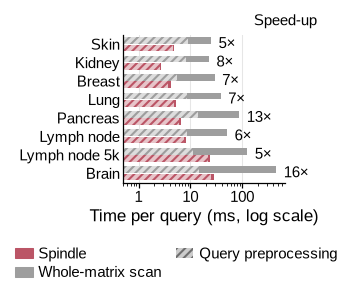

In [3]:
HATCH = "//////"
BH = 0.36  # bar height (rows are 1 apart): whole-matrix scan above, Spindle below


def tint(c, f=0.35):
    from matplotlib.colors import to_rgb
    return tuple(f * x + (1 - f) for x in to_rgb(c))


def panel_timing(fig):
    W, H = ps.size_mm(fig)
    right = 9.0
    x0 = 0.5  # ms, the axis start
    ax = ps.axes(fig, left=18.5, right=right, bottom=17.0, top=4.0)
    for i, k in enumerate(KEYS):
        r = timing.loc[k]
        for off, q, e, c in ((-0.2, r.qlog_whole_ms, r.e2e_whole_ms, WHOLE),
                             (0.2, r.qlog_block_ms, r.e2e_spindle_ms, SPINDLE)):
            ax.barh(i + off, q - x0, left=x0, height=BH, color=tint(c), ec=c, lw=0, hatch=HATCH, zorder=2)
            ax.barh(i + off, e - q, left=q, height=BH, color=c, lw=0, zorder=2)
        ax.text(r.e2e_whole_ms * 1.4, i, f"{r.speedup_e2e_spindle_vs_whole:.0f}×", fontsize=ps.TICK_PT, va="center")
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlim(x0, timing.e2e_whole_ms.max() * 1.5)
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS])
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Time per query (ms, log scale)")
    fig.text(1 - right / W, 1 - 0.5 / H, "Speed-up", fontsize=ps.TICK_PT, ha="center", va="top")
    handles = [Patch(color=SPINDLE, label="Spindle"), Patch(color=WHOLE, label="Whole-matrix scan"),
               Patch(fc=tint(ps.MUTED), ec=ps.MUTED, lw=0, hatch=HATCH, label="Query preprocessing")]
    fig.legend(handles=handles, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.5 / H), columnspacing=1.0,
               handletextpad=0.4, handlelength=1.2)


fig = ps.panel(W_T, H_T)
panel_timing(fig)
ps.save_panel(fig, FIG, "H")
